# Dust scaling relations in nearby galaxies with pybaycor

This notebook is a guided tour of [pybaycor](https://github.com/pscicluna/pybaycor)
using real observations of dust in nearby galaxies. We start with the simplest
possible question, the correlation between two quantities measured without error,
and add one complication at a time until we fit a five-dimensional model in which
measurement uncertainties, upper limits (non-detections) and missing observations
all appear together. On the way we look at how to decide whether a correlation is
real, using the model-comparison tools that come with the package.

**The data.** [DustPedia](http://dustpedia.astro.noa.gr/) (Davies et al. 2017) is a
survey of the 875 nearby galaxies (within about 40 Mpc) that were observed by
*Herschel*. We use two of its public catalogues:

* the CIGALE fits of the UV to sub-mm spectral energy distributions with the THEMIS
  dust model of Nersesian et al. (2019), which give the **stellar mass**, **star
  formation rate (SFR)**, **dust mass** and **dust temperature** of each galaxy with
  their uncertainties;
* the compilation of global **atomic gas (HI) masses** of De Vis et al. (2019), which
  flags the galaxies that were observed but **not detected** in HI.

Dust is a small fraction of a galaxy's mass, but it reprocesses a large fraction of
its starlight, and its abundance relative to stars, gas and star formation is a
key constraint on how dust forms (in evolved stars and supernovae), grows in the
interstellar medium and is destroyed. The correlations between these quantities, and
the scatter around them, are what dust-evolution models are compared with.

**Running the notebook.** From a clone of the repository, `pixi run -e examples
examples` opens JupyterLab with everything installed; `pip install pybaycor[nutpie]
jupyterlab` also works. Executing all cells takes about 5 minutes on a laptop with
`nutpie`, half of it in the parametric-bootstrap cell of Step 6, which you can skip.

| Step | Data | What it shows |
| --- | --- | --- |
| 1 | 2-D, no uncertainties | the basic model, summaries and diagnostics |
| 2 | 2-D, with uncertainties | hierarchical model; correcting the attenuation of the correlation |
| 3 | 2-D, robust | Student-t likelihood for outliers |
| 4 | 2-D, with upper limits | censoring, and the bias of the alternatives |
| 5 | 5-D | uncertainties, upper limits and missing data together |
| 6 | 5-D and 2-D | is a correlation significant? posterior probabilities, Bayes factors, a sensitivity check, p-values |
| 7 | 5-D | going further: partial correlations |

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

import pybaycor as pbc

# The samplers log one line per fit; keep the output to what matters here.
logging.getLogger("pymc").setLevel(logging.WARNING)
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 90

SEED = 2026
print(f"pybaycor {pbc.__version__}; NUTS samplers available: {pbc.available_nuts_samplers()}")

pybaycor 0.2.2.dev17+gcacfc6922.d20261020; NUTS samplers available: ['pymc', 'nutpie']


## The data

`data/dustpedia_sample.csv` holds the 814 DustPedia galaxies that have a CIGALE fit,
with the catalogue values in linear units. It was built from the CDS tables by
`data/build_dustpedia_sample.py`, which you can run to regenerate it.

To keep the fits quick we use a distance-limited sub-sample: the 229 galaxies within
15 Mpc. It contains every morphological type, from ellipticals to irregular dwarfs.

In [2]:
catalogue = pd.read_csv("data/dustpedia_sample.csv", comment="#")
galaxies = catalogue[catalogue["dist_mpc"] < 15].reset_index(drop=True)
print(f"{len(galaxies)} of {len(catalogue)} galaxies are within 15 Mpc")
galaxies.head()

229 of 814 galaxies are within 15 Mpc


,name,hubble_type,dist_mpc,sfr,e_sfr,mstar,e_mstar,mdust,e_mdust,tdust,e_tdust,mhi,e_mhi,hi_flag
0,ESO097-013,3.3,4.207,2.105e+01,1.007e+01,1.969e+10,1.007e+10,6.896e+06,1.484e+06,24.43,1.172,2.732e+09,4.303e+08,0.0
1,ESO209-009,6.1,12.589,4.673e-01,6.426e-01,1.361e+10,5.210e+09,1.452e+07,2.247e+06,22.49,0.605,3.456e+09,9.837e+07,0.0
2,ESO289-020,4.6,12.725,1.614e-02,2.771e-03,5.369e+07,3.918e+07,1.680e+05,1.911e+05,24.36,10.100,NaN,NaN,NaN
3,ESO351-030,-4.8,0.084,2.672e-09,4.260e-09,5.212e+02,3.323e+02,2.681e-01,6.737e-01,29.89,7.151,2.660e+05,2.461e+03,0.0
4,ESO358-051,0.3,14.300,7.725e-02,1.292e-02,6.541e+08,2.407e+08,4.592e+05,9.004e+04,23.35,1.131,1.351e+08,3.861e+07,0.0


Scaling relations are linear in log space, so we work with $\log_{10}$ of the masses
and the SFR. The catalogues quote symmetric uncertainties $\delta x$ in linear units,
which we propagate to first order, $\sigma_{\log x} = \delta x / (x \ln 10)$.

That approximation is fine for well-measured quantities but not for dust masses of
galaxies with little or no detected dust, whose relative uncertainty exceeds 100%. A
more careful analysis could use asymmetric uncertainties in log space
(`sigma_lower=`/`sigma_upper=`, a two-piece Normal), or treat dust masses that are
consistent with zero as upper limits. Here we keep the simple version: these points
get large uncertainties, and we will see that the model handles them gracefully.

The **HI flag** distinguishes three cases, and the difference between them is the
crux of this notebook:

* **detected** (flags 0 and 3): an HI mass with an uncertainty. For a few galaxies
  the literature gives no uncertainty; pybaycor treats an entry with uncertainty `0`
  (or `NaN`) as exact, so we can mix them with the uncertain ones;
* **upper limit** (flag 1): the galaxy was observed but not detected, and the
  quoted mass is an upper limit. This is a *censored* measurement: we know the true
  value is below the limit;
* **no HI data** (no flag, or flag 2 for confused observations): we know nothing about
  the HI mass. This is a *missing* value.

In [3]:
LN10 = np.log(10.0)


def log_with_error(value, error):
    """Return log10(value) and the first-order uncertainty in dex."""
    value = np.asarray(value, dtype=float)
    return np.log10(value), np.asarray(error, dtype=float) / (value * LN10)


log_mstar, err_log_mstar = log_with_error(galaxies["mstar"], galaxies["e_mstar"])
log_sfr, err_log_sfr = log_with_error(galaxies["sfr"], galaxies["e_sfr"])
log_mdust, err_log_mdust = log_with_error(galaxies["mdust"], galaxies["e_mdust"])
log_mhi, err_log_mhi = log_with_error(galaxies["mhi"], galaxies["e_mhi"])
t_dust, err_t_dust = galaxies["tdust"].to_numpy(), galaxies["e_tdust"].to_numpy()

hi_detected = galaxies["hi_flag"].isin([0, 3]).to_numpy()
hi_upper_limit = (galaxies["hi_flag"] == 1).to_numpy()
hi_missing = ~(hi_detected | hi_upper_limit)

hi_status = pd.Series(
    np.select([hi_detected, hi_upper_limit], ["detected", "upper limit"], "no HI data"),
    name="HI status",
)
pd.crosstab(
    hi_status,
    pd.cut(galaxies["hubble_type"], [-6, 0.5, 11], labels=["early type (T<0.5)", "late type"]),
    margins=True,
)

hubble_type,early type (T<0.5),late type,All
HI status,,,
detected,27,156,183
no HI data,16,7,23
upper limit,19,4,23
All,62,167,229


About 10% of the galaxies are HI non-detections and another 10% have no HI data.
Both groups are dominated by early-type galaxies, which are gas-poor and less
often targeted by HI surveys. Keep this in mind; we return to it in Step 5.

## Step 1 - Two variables without uncertainties

We begin with one of the tightest dust scaling relations: dust mass against stellar
mass. For now we ignore the uncertainties and treat the catalogue values as exact.

`BayesianCorrelation` takes an `(n_points, n_dim)` array. The model is a bivariate
Normal for the data, with weakly informative priors on the means and widths, and an
LKJ prior on the correlation matrix. The LKJ shape `eta=2` (the default) gently
favours smaller correlations over values close to $\pm 1$. The data are standardised
internally, so the priors make sense for any units, and all results are reported in
the original units.

In [4]:
names_2d = ["log_Mstar", "log_Mdust"]
step1 = pbc.BayesianCorrelation(np.column_stack([log_mstar, log_mdust]), names=names_2d)
print(step1.describe())
trace = step1.fit(random_seed=SEED, progressbar=False)

CorrelationData: 229 points x 2 variables
  log_Mstar: 0 uncertain
  log_Mdust: 0 uncertain
Model: observed, 0 latent values, standardised


`fit()` runs NUTS (with `nutpie` when it is installed) and stores the posterior, an
ArviZ `DataTree`, as `step1.trace`. Before looking at the answer, check that the
sampler converged: $\hat R$ close to 1 (below about 1.01) and effective sample
sizes (`ess_bulk`, `ess_tail`) of several hundred or more.

In [5]:
step1.summarise(printout=False)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu[log_Mstar],9.252,0.080,9.128,9.379,2135.285,2538.377,1.001,0.002,0.001
mu[log_Mdust],5.724,0.088,5.584,5.859,2252.323,2413.293,1.001,0.002,0.001
chol_stds[log_Mstar],1.234,0.058,1.145,1.332,2624.784,2536.053,1.000,0.001,0.001
chol_stds[log_Mdust],1.359,0.064,1.263,1.467,2356.242,2497.834,1.000,0.001,0.001
"chol_corr[log_Mstar, log_Mstar]",1.000,0.000,1.000,1.000,4000.000,4000.000,NaN,0.000,NaN
"chol_corr[log_Mstar, log_Mdust]",0.809,0.023,0.771,0.844,2793.738,2643.375,1.001,0.000,0.000
"chol_corr[log_Mdust, log_Mstar]",0.809,0.023,0.771,0.844,2793.738,2643.375,1.001,0.000,0.000
"chol_corr[log_Mdust, log_Mdust]",1.000,0.000,1.000,1.000,3830.471,3531.699,1.001,0.000,0.000


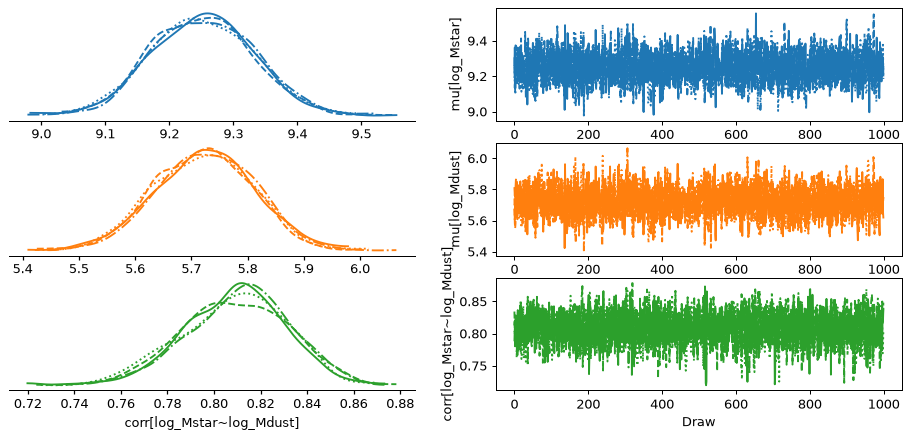

In [6]:
fig = step1.plot_trace()

The chains agree and mix well. `correlation_summary()` gives one row per pair of
variables: the posterior mean, median and standard deviation of the correlation
coefficient $\rho$, a credible interval (89% equal-tailed by default, following
ArviZ), the probability that $\rho > 0$, and a Bayes factor; we explain the last two
in Step 6. For comparison, the classical Pearson coefficient is printed too.

In [7]:
display(step1.correlation_summary())
r, p = stats.pearsonr(log_mstar, log_mdust)
print(f"Pearson r = {r:.3f} (p = {p:.1e})")

,i,j,mean,median,sd,eti_5.5%,eti_94.5%,prob_positive,bf10
pair,,,,,,,,,
log_Mstar~log_Mdust,0,1,0.809,0.81,0.023,0.771,0.844,1.0,inf


Pearson r = 0.815 (p = 9.6e-56)


With no measurement errors and a large sample, the Bayesian estimate agrees with the
Pearson coefficient, but it comes with a full posterior distribution. `plot_data()`
draws the data with the 95% region of the inferred bivariate Normal.

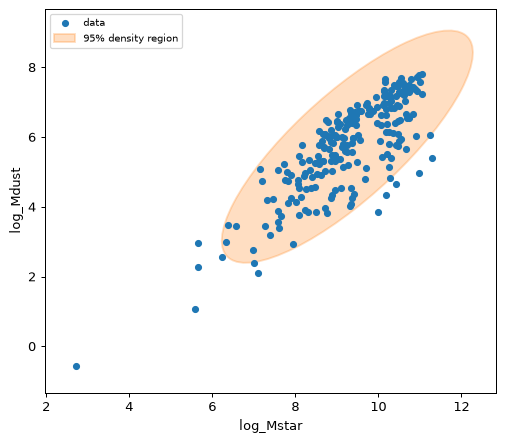

In [8]:
fig = step1.plot_data()

## Step 2 - Adding measurement uncertainties

The dust masses of gas-poor galaxies are poorly constrained. Some error bars span
more than an order of magnitude. Measurement errors scatter the points and
therefore *attenuate* the observed correlation: the correlation between the true
values is stronger than the one in the noisy data.

Passing `sigma` (one uncertainty per entry, in the same units as the data) turns the
model into a hierarchical one (Matzke et al. 2017). Each galaxy gets latent true
values drawn from the bivariate Normal, and the observations scatter around them
with the quoted uncertainties.

In [9]:
step2 = pbc.BayesianCorrelation(
    np.column_stack([log_mstar, log_mdust]),
    sigma=np.column_stack([err_log_mstar, err_log_mdust]),
    names=names_2d,
)
print(step2.describe())
step2.fit(random_seed=SEED, progressbar=False)
display(step2.correlation_summary())

CorrelationData: 229 points x 2 variables
  log_Mstar: 229 uncertain
  log_Mdust: 229 uncertain
Model: latent, 458 latent values, standardised


,i,j,mean,median,sd,eti_5.5%,eti_94.5%,prob_positive,bf10
pair,,,,,,,,,
log_Mstar~log_Mdust,0,1,0.896,0.897,0.016,0.868,0.919,1.0,inf


The correlation of the true values is stronger, $\rho \approx 0.90$ instead of
$0.81$, and the posterior is narrower. The plot shows why. Each orange point is the
posterior mean of a galaxy's *true* values, and the thin lines connect it to the
observation. Galaxies with large dust-mass uncertainties are pulled towards the
relation defined by the well-measured ones. This "shrinkage" is the model using
what the population says about galaxies of a given stellar mass to refine each
poorly measured dust mass.

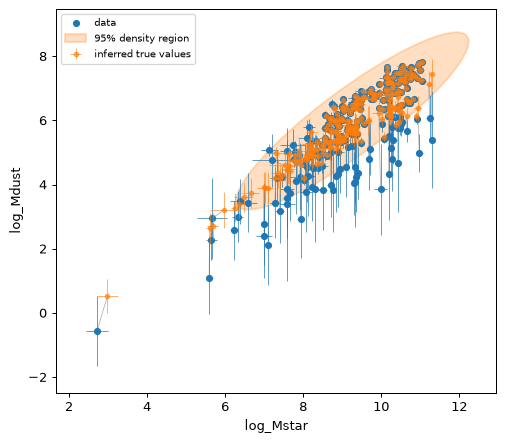

In [10]:
fig = step2.plot_data()

The inferred true values are available as `inferred_values()` (posterior mean and
standard deviation) and as the trace variable `vals`. For the galaxy with the
most uncertain dust mass:

In [11]:
true_mean, true_sd = step2.inferred_values()
k = int(np.argmax(err_log_mdust))
print(
    f"{galaxies['name'][k]}: observed log Mdust = {log_mdust[k]:.2f} ± {err_log_mdust[k]:.2f}, "
    f"inferred {true_mean[k, 1]:.2f} ± {true_sd[k, 1]:.2f}"
)

ESO471-006: observed log Mdust = 3.38 ± 2.39, inferred 4.56 ± 0.52


If you suspect that the quoted uncertainties are systematically over- or
under-estimated, `error_scale=True` adds one multiplicative correction factor per
variable and infers it from the data.

## Step 3 - Robustness against outliers

A Normal model can be pulled around by a few outliers. With `robust=True` the true
values follow a multivariate Student-t distribution instead. Its degrees of freedom
$\nu$ are inferred: small $\nu$ means heavy tails, and large $\nu$ (above about 30)
is practically Normal.

In [12]:
step3 = pbc.BayesianCorrelation(
    np.column_stack([log_mstar, log_mdust]),
    sigma=np.column_stack([err_log_mstar, err_log_mdust]),
    names=names_2d,
    robust=True,
)
step3.fit(random_seed=SEED, progressbar=False)
display(step3.correlation_summary())
display(step3.summarise(var_names=["nu"], printout=False))

,i,j,mean,median,sd,eti_5.5%,eti_94.5%,prob_positive,bf10
pair,,,,,,,,,
log_Mstar~log_Mdust,0,1,0.887,0.889,0.018,0.856,0.913,1.0,inf


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
nu,19.499,14.264,7.72,42.97,1496.804,1730.565,1.004,0.372,0.624


$\nu \approx 20$: the tails are a little heavier than Normal, and the correlation
barely moves. The plots of Steps 1 and 2 do contain one conspicuous outlier: the
point at $\log M_\star \approx 2.7$ is ESO351-030, the Sculptor dwarf spheroidal at 84
kpc. Its catalogue stellar mass of about 500 M$_\odot$ is far below literature values
(a few $10^6$ M$_\odot$), presumably a photometry problem for such an extended,
nearby object. Real catalogues contain such points. A robust model limits their
influence without having to find and remove each one by hand. It costs little, so it
is a sensible default for heterogeneous samples like this one, and we use it for the
full model below.

## Step 4 - Upper limits (censored data)

Next, stellar mass against HI mass. 23 galaxies were observed in HI but not
detected. There are three common ways of dealing with them:

1. drop the non-detections;
2. use the upper limits as if they were detections;
3. model them as **censored**: the true value lies somewhere below the limit.

pybaycor does the third. Censoring is specified per entry with a `censoring` array
(`-1` for an upper limit, `1` for a lower limit, `0` for an observed value) or with
explicit `lower=`/`upper=` bounds, which also allow interval censoring. Here the HI
limits have no measurement uncertainty of their own, so they constrain the true
value to lie below the limit exactly. A censored entry with `sigma > 0` would instead
be modelled as a noisy measurement that fell below the limit.

We leave out the galaxies without HI data for now.

In [13]:
names_hi = ["log_Mstar", "log_MHI"]
observed_hi = hi_detected | hi_upper_limit
xy = np.column_stack([log_mstar, log_mhi])
# Detected HI masses without a quoted uncertainty are treated as exact (sigma = 0).
err_log_mhi_obs = np.where(hi_detected, np.nan_to_num(err_log_mhi, nan=0.0), 0.0)
xy_err = np.column_stack([err_log_mstar, err_log_mhi_obs])

drop = pbc.BayesianCorrelation(xy[hi_detected], sigma=xy_err[hi_detected], names=names_hi)
as_detections = pbc.BayesianCorrelation(xy[observed_hi], sigma=xy_err[observed_hi], names=names_hi)
censoring = np.zeros(xy.shape, dtype=int)
censoring[hi_upper_limit, 1] = -1  # the HI mass is an upper limit
censored = pbc.BayesianCorrelation(
    xy[observed_hi],
    sigma=xy_err[observed_hi],
    censoring=censoring[observed_hi],
    names=names_hi,
)
print(censored.describe())

treatments = {
    "drop non-detections": drop,
    "limits as detections": as_detections,
    "censored (pybaycor)": censored,
}
rows = {}
for label, model in treatments.items():
    model.fit(random_seed=SEED, progressbar=False)
    row = model.correlation_summary().iloc[0]
    mu_hi = model.summarise(var_names=["mu"], printout=False)["mean"].iloc[1]
    rows[label] = {
        "n_galaxies": model.npoints,
        "rho_mean": row["mean"],
        "rho_sd": row["sd"],
        "mean log MHI": mu_hi,
    }
pd.DataFrame(rows).T

CorrelationData: 206 points x 2 variables
  log_Mstar: 206 uncertain
  log_MHI: 166 uncertain, 23 upper limits
Model: augmented, 395 latent values, standardised


,n_galaxies,rho_mean,rho_sd,mean log MHI
drop non-detections,183.0,0.670,0.041,8.589
limits as detections,206.0,0.594,0.045,8.505
censored (pybaycor),206.0,0.546,0.050,8.451


The non-detections are mostly massive early-type galaxies with little gas, so they
lie *below* the relation of the detected galaxies. Dropping them makes the
correlation look tighter than it is ($\rho \approx 0.67$) and biases the mean HI mass
upwards. Using the limits as detections is better but still overestimates $\rho$,
because the true HI masses can lie well below the limits. The censored model uses the
information correctly, and gives $\rho \approx 0.55$. The difference between the
first and last rows is more than twice the posterior uncertainty.

In the plot, upper limits are open markers with arrows pointing towards the allowed
values, and their inferred true values (orange) sit below the limits.

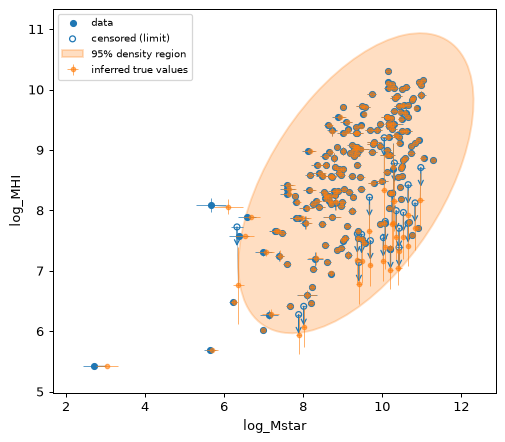

In [14]:
fig = censored.plot_data()

## Step 5 - The full problem: five variables, upper limits and missing data

Now we model five quantities together: stellar mass, SFR, dust mass, HI mass and dust
temperature. Every entry has a measurement uncertainty, 23 HI masses are upper
limits, and 23 galaxies have no HI data at all.

**Missing values are entered as `NaN`.** A `NaN` in the data *without* a censoring
bound means "not observed". pybaycor treats it as **missing at random** (MAR) and
infers it as a latent value from the other variables of that galaxy and the
population correlations. Nothing has to be thrown away: the galaxies without HI
still inform the correlations between the other four quantities. In two dimensions a
missing value carries almost no information about $\rho$. In five dimensions, the
four observed quantities predict the missing one.

Two warnings that matter in practice:

* **A non-detection is not a missing value.** Never enter an upper limit as `NaN`:
  it carries real information (the value is *small*), and imputing it as if it were
  missing at random biases the result, as Step 4 showed. Flag it as censored.
* **MAR is an assumption.** It allows the probability that a value is missing to
  depend on the *observed* variables, but not on the missing value itself. Here the
  galaxies without HI data are mostly early types. Since morphology correlates with
  stellar mass, SFR and dust content, which are all in the model, MAR is a reasonable
  approximation. It would fail if, say, HI surveys had avoided galaxies *because*
  their HI was expected to be faint at a given stellar mass and SFR.

In [15]:
names_5d = ["log_Mstar", "log_SFR", "log_Mdust", "log_MHI", "T_dust"]
data_5d = np.column_stack(
    [log_mstar, log_sfr, log_mdust, np.where(hi_missing, np.nan, log_mhi), t_dust]
)
sigma_5d = np.column_stack([err_log_mstar, err_log_sfr, err_log_mdust, err_log_mhi_obs, err_t_dust])
censoring_5d = np.zeros(data_5d.shape, dtype=int)
censoring_5d[hi_upper_limit, 3] = -1

full = pbc.BayesianCorrelation(
    data_5d, sigma=sigma_5d, censoring=censoring_5d, names=names_5d, robust=True
)
print(full.describe())

CorrelationData: 229 points x 5 variables
  log_Mstar: 229 uncertain
  log_SFR: 229 uncertain
  log_Mdust: 229 uncertain
  log_MHI: 166 uncertain, 23 missing, 23 upper limits
  T_dust: 229 uncertain
Model: augmented, 1128 latent values, robust (Student-t), standardised


`describe()` confirms what goes into the model: 23 missing and 23 censored HI masses,
and 1128 latent true values. The sampler explores all of them along with the
population parameters. With this many latent values the posterior is harder to
explore, so we give NUTS a longer warm-up than the default. The fit takes about a
minute.

In [16]:
full.fit(draws=2000, tune=3000, random_seed=SEED, progressbar=False)


def convergence(model):
    """Largest R-hat and smallest bulk ESS, overall and for the correlations."""
    table = model.summarise(printout=False)
    corr = table[table.index.str.startswith("chol_corr")]
    return (
        f"max R-hat {table['r_hat'].max():.3f} (correlations: {corr['r_hat'].max():.3f}), "
        f"min bulk ESS {table['ess_bulk'].min():.0f}"
    )


print(convergence(full))

max R-hat 1.012 (correlations: 1.005), min bulk ESS 515


The correlation matrix in one picture: posterior means, with the credible intervals
in the table below.

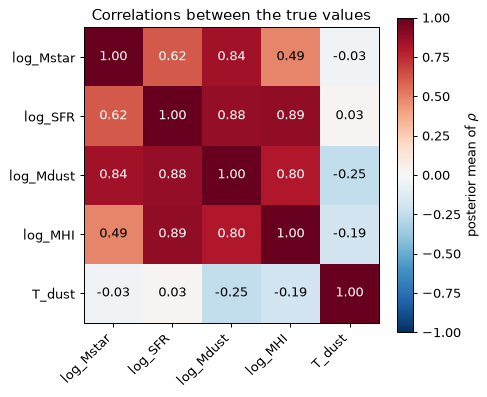

In [17]:
corr_samples = full.trace["posterior"]["chol_corr"].to_numpy()  # (chain, draw, 5, 5)
corr_mean = corr_samples.mean(axis=(0, 1))

fig, ax = plt.subplots(figsize=(5.5, 4.6))
image = ax.imshow(corr_mean, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(names_5d)):
    for j in range(len(names_5d)):
        value = corr_mean[i, j]
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "black",
        )
ax.set_xticks(range(len(names_5d)), names_5d, rotation=45, ha="right")
ax.set_yticks(range(len(names_5d)), names_5d)
fig.colorbar(image, ax=ax, label="posterior mean of $\\rho$")
ax.set_title("Correlations between the true values")
fig.tight_layout()

In [18]:
pair_summary = full.correlation_summary()
pair_summary

,i,j,mean,median,sd,eti_5.5%,eti_94.5%,prob_positive,bf10
pair,,,,,,,,,
log_Mstar~log_SFR,0,1,0.616,0.617,0.044,0.543,0.683,1.000,inf
log_Mstar~log_Mdust,0,2,0.843,0.845,0.023,0.804,0.877,1.000,inf
log_Mstar~log_MHI,0,3,0.490,0.493,0.055,0.399,0.575,1.000,2.730e+162
log_Mstar~T_dust,0,4,-0.032,-0.033,0.094,-0.181,0.122,0.360,2.577e-01
log_SFR~log_Mdust,1,2,0.880,0.881,0.018,0.850,0.907,1.000,inf
log_SFR~log_MHI,1,3,0.887,0.888,0.017,0.858,0.912,1.000,inf
log_SFR~T_dust,1,4,0.030,0.030,0.095,-0.122,0.183,0.615,2.632e-01
log_Mdust~log_MHI,2,3,0.799,0.801,0.028,0.753,0.842,1.000,inf
log_Mdust~T_dust,2,4,-0.248,-0.252,0.090,-0.386,-0.101,0.004,7.896e+00


The masses and the SFR are all strongly correlated: galaxies with more stars tend
to have more gas, form more stars and hold more dust. The dust temperature behaves
differently. Taken at face value, it is not correlated with stellar mass or SFR, and
weakly *anti*-correlated with dust and HI mass. Step 6 shows that this is misleading.

`plot_data()` shows every pair. Missing HI masses appear as rug marks on the axes
(the other coordinate is known), and upper limits as arrows.

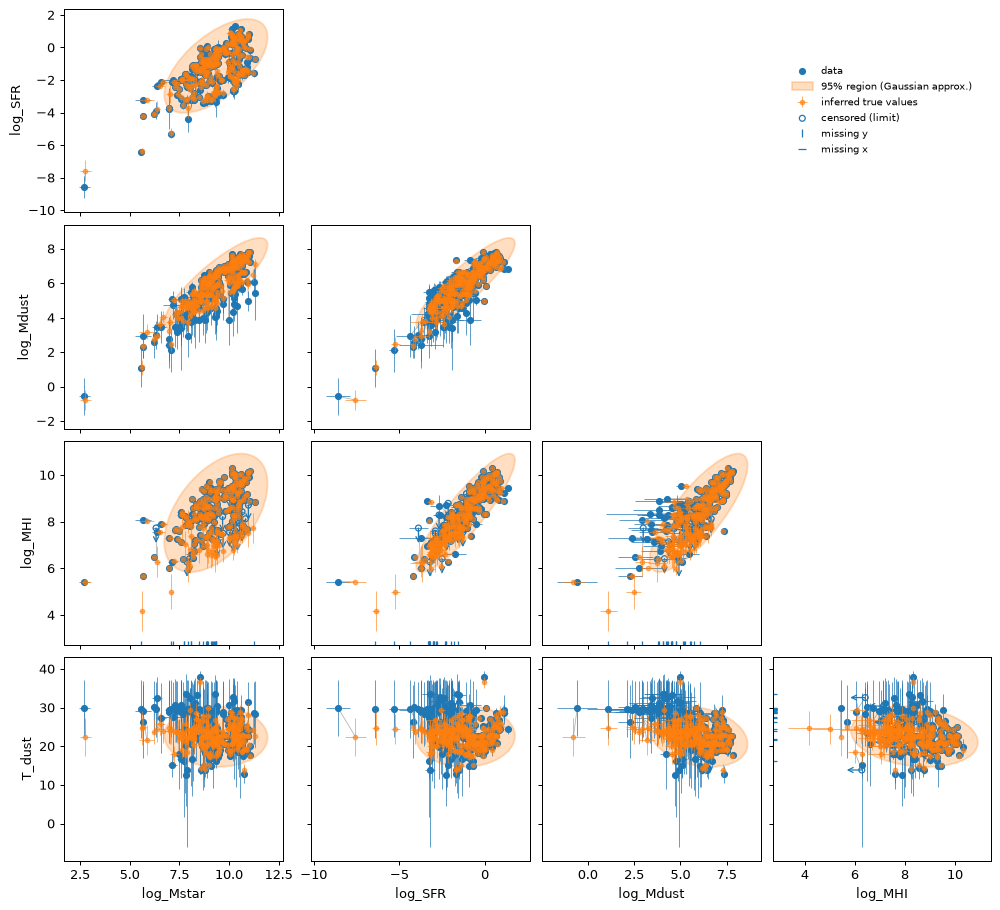

In [19]:
fig = full.plot_data()
fig.set_size_inches(11, 10)

What did the model infer for the galaxies without HI data? Their imputed HI masses
(posterior mean and standard deviation) mostly lie *below* the relation of the
detected galaxies, close to the upper limits. The model has worked out that they are
gas-poor: these are mostly early types with low SFRs and dust masses, and SFR and
dust mass predict the HI mass well. The imputed uncertainties are larger than those
of detections, but much smaller than the spread of the population.

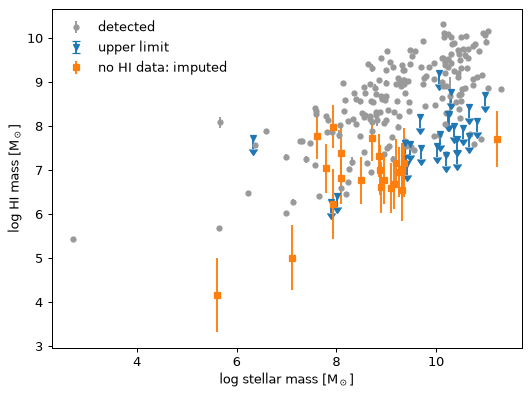

In [20]:
vals_mean, vals_sd = full.inferred_values()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.errorbar(
    log_mstar[hi_detected],
    log_mhi[hi_detected],
    yerr=err_log_mhi_obs[hi_detected],
    fmt="o",
    ms=4,
    color="0.6",
    label="detected",
)
ax.errorbar(
    log_mstar[hi_upper_limit],
    log_mhi[hi_upper_limit],
    yerr=0.25,
    uplims=True,
    fmt="v",
    ms=5,
    color="C0",
    label="upper limit",
)
ax.errorbar(
    vals_mean[hi_missing, 0],
    vals_mean[hi_missing, 3],
    yerr=vals_sd[hi_missing, 3],
    fmt="s",
    ms=5,
    color="C1",
    label="no HI data: imputed",
)
ax.set_xlabel("log stellar mass [M$_\\odot$]")
ax.set_ylabel("log HI mass [M$_\\odot$]")
ax.legend(frameon=False)
fig.tight_layout()

## Step 6 - Is a correlation significant?

A posterior that excludes zero suggests a real correlation, but "how strongly do the
data support a correlation?" deserves a direct answer. pybaycor provides three tools,
in increasing order of cost.

**1. The posterior probability of a positive correlation**, `prob_positive` in
`correlation_summary()`, is $P(\rho > 0 \mid \text{data})$. A value near 0 or 1 means
that the sign of the correlation is well established. It answers "which sign?", not
"is there a correlation at all?".

**2. The Bayes factor** `bf10` compares two models: $H_1$, in which $\rho$ is free
with its LKJ prior, and $H_0$, the same model with $\rho = 0$. For this nested pair
the Bayes factor reduces to the Savage-Dickey density ratio,

$$\mathrm{BF}_{10} = \frac{p(\rho = 0 \mid H_1)}{p(\rho = 0 \mid \text{data}, H_1)},$$

the prior density at zero divided by the posterior density at zero. It is computed
from the posterior samples we already have. Unlike a p-value, a Bayes factor can
also provide evidence *for* the null: $\mathrm{BF}_{10} < 1$ means the data prefer
$\rho = 0$. A common reading (after Jeffreys 1961; Lee & Wagenmakers 2013) is:

| $\mathrm{BF}_{10}$ | evidence |
| --- | --- |
| < 1/10 | strong for $\rho = 0$ |
| 1/10 - 1/3 | moderate for $\rho = 0$ |
| 1/3 - 3 | inconclusive |
| 3 - 10 | moderate for a correlation |
| > 10 | strong for a correlation |

An infinite value means that the posterior density at zero is numerically zero: the
evidence is overwhelming. The pairs involving the dust temperature are the
interesting ones here.

In [21]:
temperature_pairs = pair_summary.loc[pair_summary.index.str.contains("T_dust")]
temperature_pairs[["mean", "sd", "prob_positive", "bf10"]]

,mean,sd,prob_positive,bf10
pair,,,,
log_Mstar~T_dust,-0.032,0.094,0.360,0.258
log_SFR~T_dust,0.030,0.095,0.615,0.263
log_Mdust~T_dust,-0.248,0.090,0.004,7.896
log_MHI~T_dust,-0.191,0.087,0.018,1.996


Taken at face value, all three verdicts appear:

* dust mass and dust temperature: $\mathrm{BF}_{10} \approx 8$, **moderate evidence
  for an anti-correlation**;
* HI mass and dust temperature: $\mathrm{BF}_{10} \approx 2$, **inconclusive**, even
  though $P(\rho < 0) \approx 0.98$. A credible interval that excludes zero is not the
  same as strong evidence for a correlation;
* stellar mass or SFR and dust temperature: $\mathrm{BF}_{10} \approx 1/4$, **moderate
  evidence for no correlation**.

We will see shortly that these conclusions do not survive a closer look at the data.
First, three practical points about Bayes factors.

**The Bayes factor of a single pair** is also available directly. `ref_val` tests a
value other than zero:

In [22]:
i, j = names_5d.index("log_Mdust"), names_5d.index("T_dust")
print(f"BF10 against rho = 0:    {full.bayes_factor(i, j):.1f}")
print(f"BF10 against rho = -0.5: {full.bayes_factor(i, j, ref_val=-0.5):.1f}")

BF10 against rho = 0:    7.9
BF10 against rho = -0.5: 9.6


The data disfavour a strong anti-correlation of $-0.5$ about as much as they
disfavour no correlation at all.

**Bayes factors from posterior samples are noisy when zero is in the tail.** The
posterior density at zero is estimated with a kernel density estimate. When zero
lies several standard deviations from the posterior mean, only a few samples land
near it, and the estimate is uncertain. `pbc.bayes_factor()` works on any array of
samples, so a quick check is to compute it chain by chain:

In [23]:
eta = full.info.priors["eta"]
for a, b in [("log_Mdust", "T_dust"), ("log_MHI", "T_dust"), ("log_Mstar", "T_dust")]:
    i, j = names_5d.index(a), names_5d.index(b)
    per_chain = [
        pbc.bayes_factor(chain[:, i, j], eta=eta, n_dim=len(names_5d)) for chain in corr_samples
    ]
    print(f"{a} ~ {b}: BF10 per chain = {np.round(per_chain, 2)}")

log_Mdust ~ T_dust: BF10 per chain = [7.53 7.13 7.03 7.6 ]
log_MHI ~ T_dust: BF10 per chain = [2.03 1.69 1.88 2.56]
log_Mstar ~ T_dust: BF10 per chain = [0.25 0.27 0.27 0.25]


Where the posterior straddles zero (stellar mass and temperature) the chains agree
closely. The further zero is in the tail, the more they scatter: by tens of per cent
for the HI mass-temperature pair. Report such Bayes factors to one significant figure.
Beyond $\mathrm{BF}_{10} \sim 100$ the exact number is meaningless: say "decisive".
More draws help.

**Bayes factors depend on the prior.** The Savage-Dickey ratio divides by the prior
density at zero. When the data dominate, the posterior density at zero hardly changes
with the prior, so $\mathrm{BF}_{10}$ scales with the prior density at zero. A
flatter LKJ prior (smaller `eta`) spreads its mass over large $|\rho|$ and has less
density at zero, so it gives *more* support to $\rho = 0$. In five dimensions the LKJ
marginal of each correlation is a Beta distribution on $(-1, 1)$, and its density at
zero is:

In [24]:
from pybaycor.stats import lkj_marginal_density

for eta_value in (1.0, 2.0, 4.0):
    density = float(lkj_marginal_density(0.0, eta_value, len(names_5d)))
    print(f"eta = {eta_value:g}: prior density of rho at 0 = {density:.2f}")

eta = 1: prior density of rho at 0 = 0.85
eta = 2: prior density of rho at 0 = 1.02
eta = 4: prior density of rho at 0 = 1.29


Replacing the default `eta = 2` by 1 or 4 would change the Bayes factors by about 20-25%.
That moves none of the verdicts above out of its band, although the dust
mass-temperature pair would reach the border of "strong" with `eta = 4`. Always state
the prior with a Bayes factor. If the conclusion is borderline, refit with
`priors={"eta": ...}` to check how sensitive it is.

### A sensitivity check: what are the temperature measurements telling us?

A Bayes factor is only as good as the model. In particular, pybaycor assumes that
each quoted value is a measurement of the true value with the quoted, roughly
Gaussian, uncertainty. Look again at the dust temperatures in the bottom row of
the data plot in Step 5. Many galaxies have temperatures near 29-30 K with uncertainties of 5-10 K.
These are mostly faint dwarfs with little far-infrared signal, whose fitted
temperatures are driven by the SED model's parameter grid rather than by the data.

In [25]:
poor_t = err_t_dust > 4.0
print(f"{poor_t.sum()} galaxies have sigma(T_dust) > 4 K")
pd.DataFrame(
    {
        "median T_dust [K]": [np.median(t_dust[poor_t]), np.median(t_dust[~poor_t])],
        "median log M*": [np.median(log_mstar[poor_t]), np.median(log_mstar[~poor_t])],
    },
    index=["sigma(T) > 4 K", "sigma(T) <= 4 K"],
)

82 galaxies have sigma(T_dust) > 4 K


,median T_dust [K],median log M*
sigma(T) > 4 K,28.805,8.330
sigma(T) <= 4 K,22.190,9.729


Low-mass galaxies with temperatures clustered near 29 K, whatever their properties,
will drag the inferred temperature correlations towards negative values. Their
temperatures are not measurements centred on the truth, so the error model does not
describe them.

A simple way to check this is to declare those temperatures **missing**, which is
another use of missing data: a value that the data do not constrain can be left out
without dropping the galaxy. Whether a temperature is well constrained depends on the
far-infrared signal-to-noise, and so mostly on the dust mass and distance. This is
close to the missing-at-random situation. We refit the 5-D model:

In [26]:
data_refined = data_5d.copy()
data_refined[poor_t, names_5d.index("T_dust")] = np.nan
refined = pbc.BayesianCorrelation(
    data_refined, sigma=sigma_5d, censoring=censoring_5d, names=names_5d, robust=True
)
print(refined.describe())
refined.fit(draws=2000, tune=3000, random_seed=SEED, progressbar=False)
print(convergence(refined))
refined_summary = refined.correlation_summary()
pd.concat(
    {
        "all temperatures": pair_summary[["mean", "bf10"]],
        "poorly constrained temperatures missing": refined_summary[["mean", "bf10"]],
    },
    axis=1,
).loc[temperature_pairs.index]

CorrelationData: 229 points x 5 variables
  log_Mstar: 229 uncertain
  log_SFR: 229 uncertain
  log_Mdust: 229 uncertain
  log_MHI: 166 uncertain, 23 missing, 23 upper limits
  T_dust: 147 uncertain, 82 missing
Model: augmented, 1128 latent values, robust (Student-t), standardised


max R-hat 1.007 (correlations: 1.007), min bulk ESS 638


all temperatures         \
                             mean   bf10   
pair                                       
log_Mstar~T_dust           -0.032  0.258   
log_SFR~T_dust              0.030  0.263   
log_Mdust~T_dust           -0.248  7.896   
log_MHI~T_dust             -0.191  1.996   

                 poorly constrained temperatures missing            
                                                    mean      bf10  
pair                                                                
log_Mstar~T_dust                                   0.237     6.505  
log_SFR~T_dust                                     0.403  1176.352  
log_Mdust~T_dust                                   0.112     0.486  
log_MHI~T_dust                                     0.091     0.392

The picture changes completely. With the uninformative temperatures removed:

* the dust temperature is **positively correlated with the SFR**, decisively. This is
  physically expected, since star formation heats the dust;
* there is moderate evidence that more massive galaxies have warmer dust;
* the apparent anti-correlations with dust and HI mass disappear. The Bayes factors
  are now inconclusive, leaning towards no correlation.

The correlations between masses and SFR are unchanged. The lesson is general: the
machinery quantifies the evidence *given the model*, and an error model that does not
describe the data can produce confident but wrong conclusions. Checks like this one
are part of the analysis, not an optional extra.

**3. A parametric-bootstrap p-value**, `null_pvalue()`, answers the frequentist
question "how often would data with no correlation produce an estimate this strong?".
It fits a model in which the variables are *independent*, simulates data sets with
the same uncertainties, censoring and missing entries from that fit, refits each with
the full model, and returns the fraction of simulations whose posterior mean
$|\rho|$ is at least the observed one. In more than two dimensions the null model
makes *all* variables independent, so to test one pair we use a 2-D model. The
smallest p-value it can return is $1/(n_\mathrm{sim}+1)$, so claiming $p < 0.01$ needs
at least 100 simulations. Each simulation is a complete fit. We use 30, which takes a
few minutes; this is the slowest cell in the notebook.

,mean,sd,prob_positive,bf10
pair,,,,
log_SFR~T_dust,0.348,0.115,0.997,11.542


observed mean |rho| = 0.348; p = 0.032


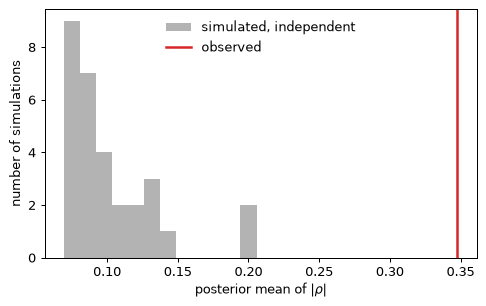

In [27]:
sfr_tdust = pbc.BayesianCorrelation(
    np.column_stack([log_sfr, data_refined[:, names_5d.index("T_dust")]]),
    sigma=np.column_stack([err_log_sfr, err_t_dust]),
    names=["log_SFR", "T_dust"],
    robust=True,
)
sfr_tdust.fit(random_seed=SEED, progressbar=False)
display(sfr_tdust.correlation_summary()[["mean", "sd", "prob_positive", "bf10"]])

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # convergence warnings from the short refits
    pvalue, null_stats = sfr_tdust.null_pvalue(
        n_sim=30, random_seed=SEED, return_null_distribution=True
    )
observed_stat = np.abs(sfr_tdust.correlation()).mean()
print(f"observed mean |rho| = {observed_stat:.3f}; p = {pvalue:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.hist(null_stats, bins=12, color="0.7", label="simulated, independent")
ax.axvline(observed_stat, color="C3", lw=2, label="observed")
ax.set_xlabel("posterior mean of $|\\rho|$")
ax.set_ylabel("number of simulations")
ax.legend(frameon=False)
fig.tight_layout()

None of the simulated data sets without a correlation produced an estimate as large
as the observed one, so $p$ is at its floor of $1/31$: the correlation is significant
at that level, and more simulations would be needed to say how significant. The
p-value and the Bayes factor answer different questions. The p-value asks whether
data like ours would be unusual if $\rho = 0$. The Bayes factor asks how much better
$\rho \neq 0$ predicts the data than $\rho = 0$, and it can also come out in favour
of the null. Here both agree. Note also how much weaker the evidence is in this 2-D
fit than in the 5-D one: in 5-D, the other variables help to pin down the true
temperatures of the galaxies whose temperatures are missing.

**Further caveats specific to these data.** Dust temperature and dust mass come from
the same SED fit. A cooler fitted temperature needs more dust to produce the same
far-infrared emission, so the *errors* on $M_\mathrm{dust}$ and $T_\mathrm{dust}$ are
anti-correlated (Shetty et al. 2009; Kelly et al. 2012), and pybaycor assumes
independent errors on each entry. Similarly, all masses scale with the square of the
distance, so distance uncertainties, which are not included in the catalogue errors,
can induce positive correlations between the masses.

## Step 7 - Going further: partial correlations

Dust mass correlates with stellar mass, SFR and HI mass. But these are all correlated
with each other, so which relation is the most fundamental? The **partial
correlation** of two variables measures their correlation at fixed values of all the
others. For a multivariate Normal it follows from the inverse of the correlation
matrix, $P = R^{-1}$, as $\rho_{ij\cdot\text{rest}} = -P_{ij} / \sqrt{P_{ii}P_{jj}}$.

Because the posterior gives us samples of the whole correlation matrix of the *true*
values, with uncertainties, censoring and missing data accounted for, we get the
posterior of every partial correlation by inverting each sample. This is one of the
advantages of modelling all the variables jointly instead of pair by pair. We use the
refined model from the sensitivity check.

In [28]:
corr_refined = refined.trace["posterior"]["chol_corr"].to_numpy()
corr_flat = corr_refined.reshape(-1, len(names_5d), len(names_5d))
precision = np.linalg.inv(corr_flat)
diag = np.sqrt(np.einsum("sii->si", precision))
partial = -precision / (diag[:, :, None] * diag[:, None, :])

dust = names_5d.index("log_Mdust")
rows = {}
for other, name in enumerate(names_5d):
    if other == dust:
        continue
    marginal_s, partial_s = corr_flat[:, dust, other], partial[:, dust, other]
    lo, hi = np.quantile(partial_s, [0.055, 0.945])
    rows[f"log_Mdust ~ {name}"] = {
        "rho": marginal_s.mean(),
        "partial rho": partial_s.mean(),
        "89% interval": f"[{lo:.2f}, {hi:.2f}]",
        "P(partial > 0)": (partial_s > 0).mean(),
    }
pd.DataFrame(rows).T

,rho,partial rho,89% interval,P(partial > 0)
log_Mdust ~ log_Mstar,0.848,0.949,"[0.92, 0.97]",1.0
log_Mdust ~ log_SFR,0.87,0.896,"[0.84, 0.94]",1.0
log_Mdust ~ log_MHI,0.8,-0.374,"[-0.59, -0.15]",0.006
log_Mdust ~ T_dust,0.112,-0.88,"[-0.93, -0.81]",0.0


At fixed values of the other variables, dust mass remains tightly linked to stellar
mass and SFR. Two results are more surprising, and show why partial correlations are
worth computing:

* The partial correlation with **HI mass is negative**, although the ordinary
  correlation is $+0.8$. At fixed stellar mass and SFR, galaxies with more atomic gas
  have *less* dust, so their dust-to-gas ratio is lower. This is what we expect if
  gas-rich galaxies are less chemically evolved, as found for the dust-to-gas and
  dust-to-metal ratios of DustPedia galaxies by De Vis et al. (2019).
* The partial correlation with **temperature is strongly negative**, although the
  ordinary correlation is weakly positive. At fixed SFR, which sets the heating, the
  same far-infrared emission can come from a lot of cold dust or a little warm dust:
  the energy balance of dust emission, $L_\mathrm{dust} \propto M_\mathrm{dust}
  T^{4+\beta}$. Part of this is built into the data, because CIGALE derives the SFR,
  dust mass and temperature from the same SED with an energy-balance constraint.
  Partial correlations between quantities from the same fit reflect the SED model as
  well as the galaxies.

Partial correlations come from the posterior without any new fit. A Bayes factor for
them would need the prior density of a partial correlation under the LKJ prior,
which pybaycor does not provide, so here we rely on the posterior intervals and
probabilities.

## Summary

* `BayesianCorrelation(data)` estimates the correlation matrix of any number of
  variables. `correlation_summary()`, `summarise()` and the plotting methods give
  the results and the diagnostics.
* `sigma=` adds per-entry measurement uncertainties. Exact (`0`/`NaN`) and uncertain
  entries can be mixed, and asymmetric errors use `sigma_lower=`/`sigma_upper=`.
  Accounting for errors corrects the attenuation of the correlation.
* `robust=True` uses a Student-t distribution that resists outliers.
* `censoring=` (or `lower=`/`upper=`) handles upper limits, lower limits and
  intervals. Dropping non-detections or treating limits as detections biases the
  correlation.
* `NaN` without a bound is a missing value, imputed under the missing-at-random
  assumption. Non-detections are not missing values.
* Significance: `prob_positive` for the sign, `bf10` / `bayes_factor()` for the
  evidence for a correlation (which can also favour $\rho = 0$), and `null_pvalue()`
  for a frequentist check. Report the prior with any Bayes factor, quote Bayes factors
  computed from the tail of the posterior to one significant figure, and check that
  the conclusions survive changes to the data and the model: here, uninformative dust
  temperatures reversed the apparent temperature correlations.
* The joint posterior gives partial correlations, and any other function of the
  correlation matrix, for free.

## References

* Davies J. I. et al. 2017, PASP, 129, 044102 - DustPedia
* Nersesian A. et al. 2019, A&A, 624, A80 - CIGALE fits of DustPedia galaxies
* De Vis P. et al. 2019, A&A, 623, A5 - DustPedia metallicities and HI masses
* Matzke D. et al. 2017, Collabra: Psychology, 3, 25 - correlations with measurement error
* Lewandowski D., Kurowicka D. & Joe H. 2009, J. Multivariate Anal., 100, 1989 - LKJ prior
* Lee M. D. & Wagenmakers E.-J. 2013, *Bayesian Cognitive Modeling* - Bayes factor scale
* Shetty R. et al. 2009, ApJ, 696, 676; Kelly B. C. et al. 2012, ApJ, 752, 55 -
  temperature-mass degeneracies in dust SED fits